# Risco de Mercado de uma Carteira de Ações da B3

**Objetivo:** estimar o risco de perda diária de uma carteira de 10 ações do Ibovespa
e verificar, com testes estatísticos formais, **quais metodologias de VaR funcionam de verdade**
fora da amostra, inclusive em períodos de estresse como a pandemia (março/2020).

Roteiro:
1. Dados e fatos estilizados dos retornos
2. VaR e CVaR na amostra completa (5 metodologias)
3. Decomposição do risco por ativo (Component VaR)
4. Backtesting fora da amostra: Kupiec, Christoffersen e semáforo de Basileia
5. Período de estresse: março de 2020

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from scipy import stats

import marketrisk as mr

plt.rcParams.update({
    "figure.figsize": (11, 4.5), "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "savefig.bbox": "tight",
})
pd.options.display.float_format = "{:,.4f}".format
ALPHA = 0.99

## 1. Dados

Preços de fechamento ajustados (Yahoo Finance) de jan/2012 a set/2026 para 10 ações de setores
diferentes. A carteira é **igualmente ponderada** (10% em cada ativo), rebalanceada diariamente.

In [2]:
prices = mr.load_prices(cache_dir="../data")
returns = mr.simple_returns(prices)
weights = np.full(len(prices.columns), 1 / len(prices.columns))
port = returns @ weights
port.name = "Carteira"

print(f"{len(returns)} dias úteis, de {returns.index[0]:%d/%m/%Y} a {returns.index[-1]:%d/%m/%Y}")
prices.tail()

3652 dias úteis, de 03/01/2012 a 30/09/2026


,PETR4,VALE3,ITUB4,BBDC4,BBAS3,ABEV3,WEGE3,B3SA3,RENT3,LREN3
Date,,,,,,,,,,
2026-09-24,49.2600,70.6600,41.8528,17.7618,21.5400,15.3400,50.7400,17.8200,38.1482,10.9700
2026-09-25,48.0700,70.7700,42.1127,17.8617,21.5900,15.3200,51.0700,17.9600,37.7934,11.1200
2026-09-28,48.7200,71.1600,41.6929,17.6419,21.4900,15.2000,50.1200,17.6600,38.0300,11.1600
2026-09-29,49.1000,69.6100,42.2826,17.7618,22.0400,15.2700,50.2900,17.9000,38.5300,11.3500
2026-09-30,49.1200,69.9100,44.2618,18.4910,23.0700,15.3600,49.4600,18.3400,40.5000,11.6000


In [3]:
summary = pd.DataFrame({
    "Retorno anual": returns.mean() * 252,
    "Volatilidade anual": returns.std() * np.sqrt(252),
    "Assimetria": returns.skew(),
    "Excesso de curtose": returns.kurt(),
    "Pior dia": returns.min(),
})
summary.loc["Carteira"] = [port.mean() * 252, port.std() * np.sqrt(252), port.skew(), port.kurt(), port.min()]
summary.style.format({
    "Retorno anual": "{:.1%}", "Volatilidade anual": "{:.1%}", "Assimetria": "{:.2f}",
    "Excesso de curtose": "{:.1f}", "Pior dia": "{:.1%}",
})

,Retorno anual,Volatilidade anual,Assimetria,Excesso de curtose,Pior dia
PETR4,26.0%,44.3%,-0.40,9.3,-29.7%
VALE3,17.9%,39.5%,0.16,7.5,-24.6%
ITUB4,17.9%,30.0%,-0.06,5.3,-18.0%
BBDC4,14.3%,33.4%,-0.00,8.0,-17.4%
BBAS3,18.7%,38.8%,-0.09,7.9,-21.2%
ABEV3,9.9%,25.7%,0.24,9.0,-15.8%
WEGE3,27.0%,31.3%,-0.10,8.1,-20.6%
B3SA3,22.6%,36.8%,0.17,3.7,-16.1%
RENT3,21.5%,39.2%,0.22,9.8,-23.4%
LREN3,13.7%,38.5%,-0.04,4.5,-21.1%


A diversificação reduz bastante a volatilidade: a carteira é menos volátil que quase todos os
ativos isolados. Mas o **excesso de curtose** (zero para uma normal) mostra que as caudas são
muito mais pesadas do que a distribuição normal prevê, e é exatamente na cauda que o VaR mora.

### Fatos estilizados

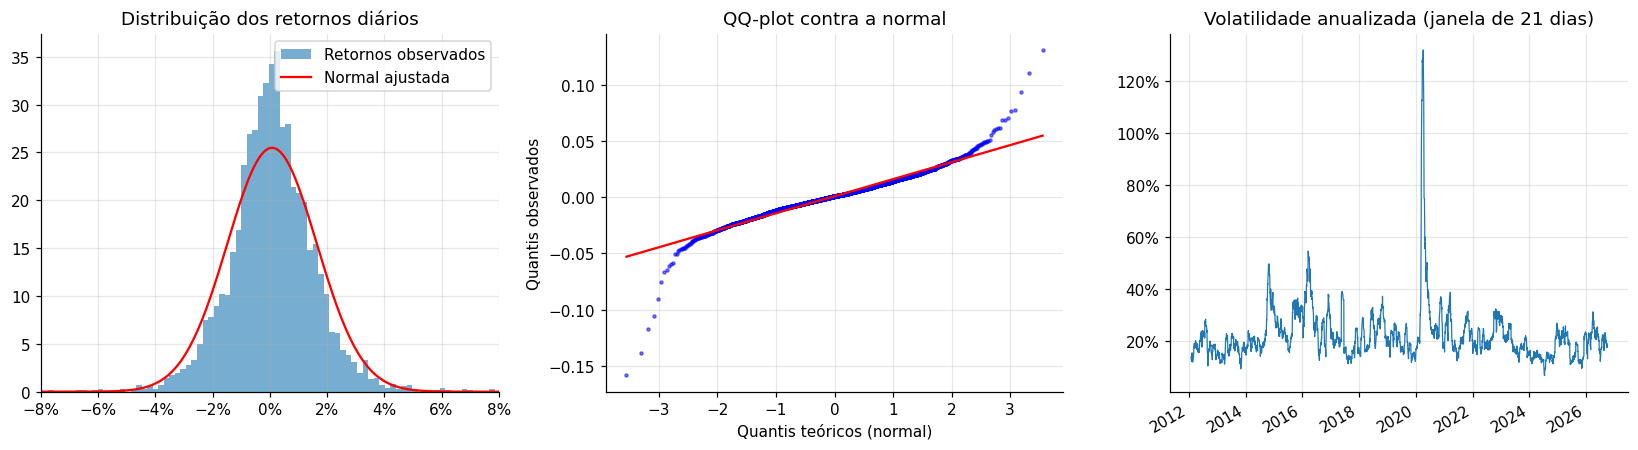

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

ax = axes[0]
ax.hist(port, bins=150, density=True, alpha=0.6, label="Retornos observados")
x = np.linspace(port.min(), port.max(), 400)
ax.plot(x, stats.norm.pdf(x, port.mean(), port.std()), "r", lw=1.5, label="Normal ajustada")
ax.set_xlim(-0.08, 0.08)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_title("Distribuição dos retornos diários")
ax.legend()

ax = axes[1]
stats.probplot(port, dist="norm", plot=ax)
ax.get_lines()[0].set(markersize=2, alpha=0.5)
ax.set_title("QQ-plot contra a normal")
ax.set_xlabel("Quantis teóricos (normal)")
ax.set_ylabel("Quantis observados")

ax = axes[2]
(port.rolling(21).std() * np.sqrt(252)).plot(ax=ax, lw=0.8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_title("Volatilidade anualizada (janela de 21 dias)")
ax.set_xlabel("")

fig.tight_layout()
fig.savefig("../figures/fatos_estilizados.png")

Três fatos que guiam a escolha do modelo:
- **Caudas pesadas:** os pontos do QQ-plot se afastam da reta nos extremos. Um VaR normal tende a subestimar perdas grandes.
- **Clusters de volatilidade:** períodos calmos e turbulentos se alternam (2015-16, 2020, 2022). Um modelo com janela fixa reage devagar a mudanças de regime.
- **Assimetria negativa:** quedas fortes são mais frequentes que altas fortes.

## 2. VaR e CVaR na amostra completa

| Método | Ideia |
|---|---|
| Histórico | Quantil empírico das perdas passadas. Não assume distribuição. |
| Paramétrico (normal) | $\text{VaR} = -(\mu + \sigma z_{1-\alpha})$ |
| Cornish-Fisher | Corrige o quantil normal pela assimetria e curtose observadas |
| Monte Carlo normal | Simula retornos multivariados com a matriz de covariância dos ativos |
| Monte Carlo t-Student | Igual ao anterior, mas com caudas pesadas (5 graus de liberdade) |

O **CVaR** (Expected Shortfall) responde à pergunta que o VaR não responde: *quando a perda passa do
VaR, de quanto ela é em média?* É a medida adotada pelo FRTB (Basileia III) para risco de mercado.

In [5]:
rng = np.random.default_rng(42)
mu_vec, cov = returns.mean().to_numpy(), returns.cov().to_numpy()

rows = {}
for a in (0.95, 0.99):
    mc_n = mr.monte_carlo_var(weights, mu_vec, cov, a, 200_000, rng=rng)
    mc_t = mr.monte_carlo_var(weights, mu_vec, cov, a, 200_000, dist="t", rng=rng)
    rows[f"VaR {a:.0%}"] = {
        "Histórico": mr.historical_var(port, a),
        "Paramétrico (normal)": mr.parametric_var(port.mean(), port.std(), a),
        "Cornish-Fisher": mr.cornish_fisher_var(port, a),
        "Monte Carlo normal": mc_n[0],
        "Monte Carlo t-Student": mc_t[0],
    }
    rows[f"CVaR {a:.0%}"] = {
        "Histórico": mr.historical_cvar(port, a),
        "Paramétrico (normal)": mr.parametric_cvar(port.mean(), port.std(), a),
        "Cornish-Fisher": np.nan,
        "Monte Carlo normal": mc_n[1],
        "Monte Carlo t-Student": mc_t[1],
    }
static = pd.DataFrame(rows)
static.style.format("{:.2%}", na_rep="–")

,VaR 95%,CVaR 95%,VaR 99%,CVaR 99%
Histórico,2.28%,3.36%,3.63%,5.66%
Paramétrico (normal),2.50%,3.15%,3.57%,4.10%
Cornish-Fisher,2.34%,–,7.36%,–
Monte Carlo normal,2.50%,3.16%,3.55%,4.08%
Monte Carlo t-Student,2.37%,3.40%,4.05%,5.37%


Para R$ 1 milhão investido, um VaR 99% de 2,5% significaria: *em 99 de cada 100 dias, a perda
não deve passar de R$ 25 mil*. Repare como, a 99%, o modelo normal fica abaixo do histórico,
e o gap cresce no CVaR: a normal subestima justamente o tamanho das perdas extremas.

## 3. De onde vem o risco? (Component VaR)

Pela decomposição de Euler, a contribuição de cada ativo é $w_i \cdot \partial \text{VaR} / \partial w_i$,
e as contribuições somam exatamente o VaR da carteira. Usamos a covariância do último ano.

VaR 99% paramétrico da carteira (último ano): 2.97%


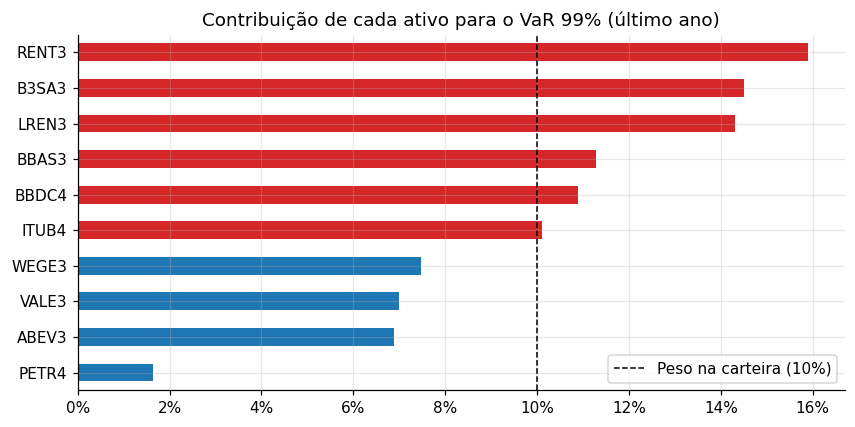

In [6]:
cov_1y = returns.iloc[-252:].cov().to_numpy()
cvar_i = pd.Series(mr.component_var(weights, cov_1y, ALPHA), index=prices.columns)
share = (cvar_i / cvar_i.sum()).sort_values()

fig, ax = plt.subplots(figsize=(9, 4.2))
colors = ["tab:red" if s > 1 / len(share) else "tab:blue" for s in share]
share.plot.barh(ax=ax, color=colors)
ax.set_ylabel("")
ax.axvline(1 / len(share), color="k", ls="--", lw=1, label="Peso na carteira (10%)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_title(f"Contribuição de cada ativo para o VaR {ALPHA:.0%} (último ano)")
ax.legend()
fig.savefig("../figures/component_var.png")

print(f"VaR 99% paramétrico da carteira (último ano): {cvar_i.sum():.2%}")

Pesos iguais **não** significam riscos iguais. Ativos em vermelho contribuem mais para o VaR do
que o seu peso na carteira, seja por volatilidade alta, seja por correlação alta com o resto.
Essa leitura é o ponto de partida para a construção de carteiras por *risk parity*
(ver o projeto de construção de carteiras).

## 4. Backtesting fora da amostra

Na prática, o que importa é se o VaR **previsto ontem** cobre a perda **realizada hoje**.
Para cada dia, estimamos o VaR 99% de 1 dia usando apenas os 252 dias anteriores
e contamos as **exceções** (dias em que a perda superou o VaR).

- **EWMA (RiskMetrics):** volatilidade com média móvel exponencial ($\lambda = 0{,}94$), que reage rápido a choques.
- **Simulação Histórica Filtrada (FHS):** padroniza os retornos passados pela volatilidade EWMA da época e reescala pela volatilidade de hoje. Junta as caudas empíricas do método histórico com a velocidade de reação do EWMA.
- **Teste de Kupiec (POF):** a frequência de exceções é compatível com 1%? (p-valor < 5% → rejeita o modelo)
- **Teste de Christoffersen:** as exceções são independentes ou vêm em clusters?
- **Semáforo de Basileia:** número de exceções nos últimos 250 dias (verde ≤ 4, amarela 5-9, vermelha ≥ 10).

In [7]:
forecasts = mr.rolling_var_forecasts(returns, weights, alpha=ALPHA, window=252, n_sims=10_000)
realized = port.loc[forecasts.index]
bt = mr.backtest_summary(realized, forecasts, ALPHA)
bt

,Dias,Exceções,Esperado,Taxa (%),Kupiec p-valor,Christoffersen p-valor,Exceções (últ. 250d),Basileia
Histórico,3400,52,34.0000,1.5300,0.0040,0.0010,4,Verde
Paramétrico,3400,53,34.0000,1.5600,0.0020,0.0000,5,Amarela
Cornish-Fisher,3400,42,34.0000,1.2400,0.1840,0.1110,3,Verde
"EWMA (λ=0,94)",3400,49,34.0000,1.4400,0.0150,0.7380,3,Verde
Monte Carlo,3400,54,34.0000,1.5900,0.0010,0.0000,6,Amarela
Hist. Filtrada (FHS),3400,42,34.0000,1.2400,0.1840,0.5480,2,Verde


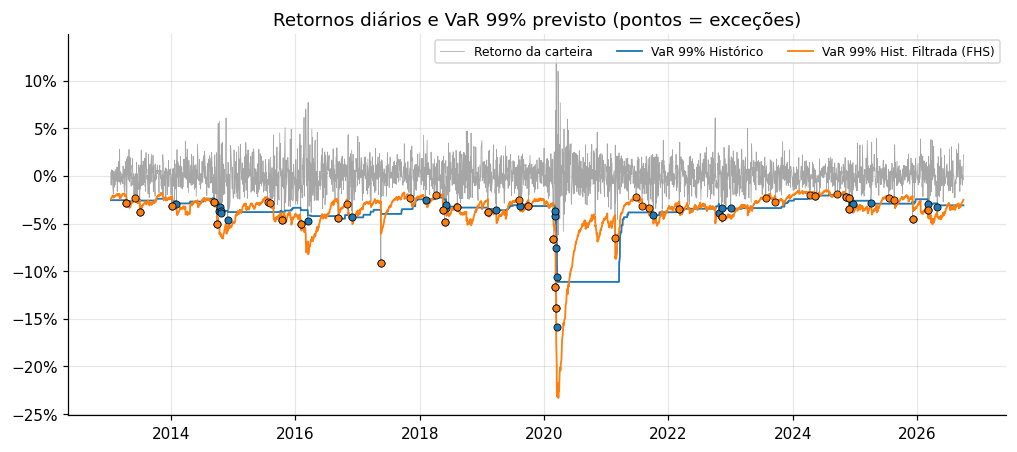

In [8]:
def plot_var(start, end, models, fname, title, bars=False):
    fig, ax = plt.subplots()
    r = realized.loc[start:end]
    if bars:
        ax.bar(r.index, r, width=0.8, color="0.65", label="Retorno da carteira")
    else:
        ax.plot(r.index, r, color="0.65", lw=0.5, label="Retorno da carteira")
    for m, color in zip(models, ["tab:blue", "tab:orange", "tab:green"]):
        f = forecasts.loc[start:end, m]
        ax.plot(f.index, -f, lw=1.2, color=color, label=f"VaR 99% {m}")
        hit = r < -f
        ax.scatter(r.index[hit], r[hit], s=22, color=color, edgecolor="k", lw=0.5, zorder=3)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.set_title(title)
    ax.legend(loc="upper right", fontsize=8, ncol=len(models) + 1)
    fig.savefig(f"../figures/{fname}")
    return ax

plot_var(None, None, ["Histórico", "Hist. Filtrada (FHS)"], "backtest_var.png",
         "Retornos diários e VaR 99% previsto (pontos = exceções)");

## 5. Estresse: a pandemia (fev-abr/2020)

,Exceções entre 20/02 e 31/03/2020
Histórico,8
Paramétrico,10
Cornish-Fisher,5
"EWMA (λ=0,94)",4
Monte Carlo,10
Hist. Filtrada (FHS),3


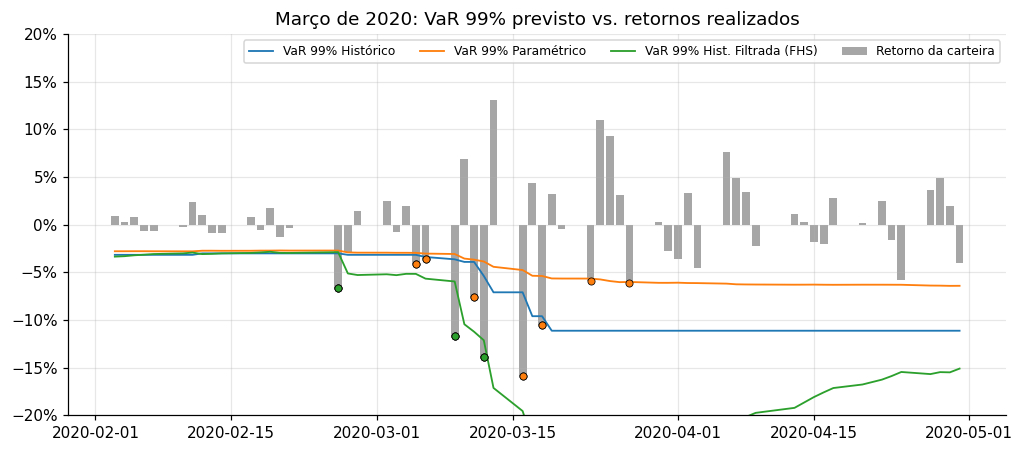

In [9]:
ax = plot_var("2020-02-01", "2020-04-30", ["Histórico", "Paramétrico", "Hist. Filtrada (FHS)"],
              "estresse_covid.png", "Março de 2020: VaR 99% previsto vs. retornos realizados", bars=True)
ax.set_ylim(-0.2, 0.2)
ax.figure.savefig("../figures/estresse_covid.png")

covid = slice("2020-02-20", "2020-03-31")
hits_covid = pd.Series({m: int(mr.exceptions(realized.loc[covid], forecasts.loc[covid, m]).sum())
                        for m in forecasts.columns}, name="Exceções entre 20/02 e 31/03/2020")
hits_covid.to_frame()

## Conclusões

1. **A normal subestima a cauda.** Na amostra completa, o VaR 99% normal (3,6%) é parecido com o histórico,
   mas o CVaR 99% normal (4,1%) fica **28% abaixo** do histórico (5,7%). A t-Student chega bem mais perto (5,4%).
2. **Janela fixa reage devagar.** Histórico, paramétrico e Monte Carlo tiveram 52-54 exceções contra 34 esperadas
   e foram rejeitados tanto por Kupiec quanto por Christoffersen: as falhas vêm em clusters, justamente nas crises.
3. **Efeito fantasma.** Depois de março/2020 o VaR histórico ficou em ~11% por um ano inteiro, até a crise sair da janela.
   Num banco, isso significaria capital alocado em excesso muito depois de o risco ter passado.
4. **Volatilidade condicional resolve os clusters.** O EWMA elimina a dependência entre exceções (Christoffersen p = 0,74),
   mas, com quantil normal, ainda erra a frequência (Kupiec p = 0,015).
5. **A Simulação Histórica Filtrada foi o melhor modelo:** 42 exceções (1,24%), aprovado nos dois testes,
   apenas 3 exceções no pior momento da pandemia (contra 10 do paramétrico) e zona verde de Basileia.
6. **Cornish-Fisher funciona em janelas de 1 ano, mas é instável com curtose extrema:** na amostra completa
   (excesso de curtose ≈ 9,5) ele dá um VaR 99% de 7,4%, o dobro do histórico.

**Próximos passos:** GARCH(1,1) com inovações t-Student, horizonte de 10 dias (regulatório) e
testes de estresse com cenários históricos (Joesley Day em mai/2017, greve dos caminhoneiros em mai/2018).

In [10]:
# Tabela de backtest exportada para o README
bt.to_csv("../figures/backtest_summary.csv")
static.to_csv("../figures/var_estatico.csv")
hits_covid.to_csv("../figures/excecoes_covid.csv")